# ScamShield
## Explainable credit-card fraud detection

This practical compares **CART**, **Random Forest**, and **XGBoost** using the same anonymized credit-card transactions. It follows the path from the supplied archive to the dashboard's alert and explanation.

**Where the code lives.** `core.py` defines input features, cleaning, time splits, scoring, and explanations. `train.py` fits and evaluates the classifiers. `app.py` serves the scores and the dashboard. The code cells below import these same functions so the guide and app use identical definitions.

Run this notebook from the project root with the project interpreter. It reads the bundled model artifacts by default. Set `RETRAIN = True` to regenerate them. The saved plots and results remain visible when the notebook is opened without a Python kernel.

In [1]:
from pathlib import Path
import json
import math

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve
from sklearn.tree import plot_tree

from core import ARTIFACTS, FEATURES, NAMES, TARGET, explain, find_data, load_data, prepare, scores, split_data
from train import build_models, run, validation_threshold

DATA = find_data()  # or find_data(r"C:\\path\\to\\archive.zip")
RETRAIN = False
if RETRAIN:
    run(DATA)

report = json.loads((ARTIFACTS / "evaluation.json").read_text(encoding="utf-8"))
models = joblib.load(ARTIFACTS / "models.joblib")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
colors = {"cart": "#546878", "forest": "#385850", "xgb": "#ad702d"}
print("Source:", DATA.name)
print("Models:", ", ".join(NAMES.values()))

Source: archive.zip
Models: CART, Random Forest, XGBoost


## 1. Inspect the data and class imbalance

The [ULB / Worldline dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) contains anonymized card transactions from roughly two days. **Time** is seconds since the first transaction. **Amount** is the transaction amount. **V1–V28** are numerical principal components released by the dataset creators. **Class** is the target, with 1 for fraud and 0 for legitimate. This project uses the supplied PCA values directly. Their original business meanings are undisclosed.

The loader reads only the 30 declared predictors and the target from the ZIP or CSV. It verifies that values are finite and that the target contains both classes. A classifier that clears every transaction can achieve high accuracy because fraud is rare, while catching zero frauds.

,count,share (%)
Legitimate,284315,99.8273
Fraud,492,0.1727


,Time,Amount,V1,V2,Class
0,0.0,149.62,-1.359807,-0.072781,0
1,0.0,2.69,1.191857,0.266151,0
2,1.0,378.66,-1.358354,-1.340163,0
3,1.0,123.50,-0.966272,-0.185226,0
4,2.0,69.99,-1.158233,0.877737,0


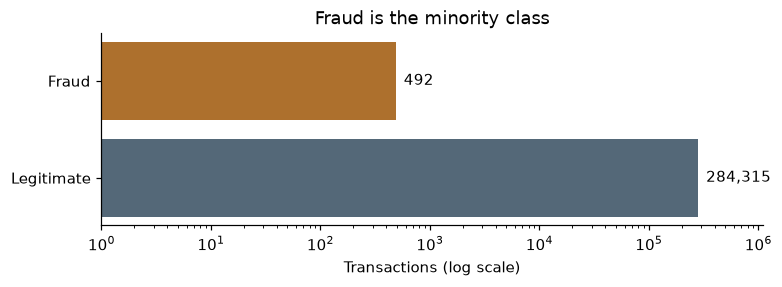

In [2]:
raw = load_data(DATA)
counts = raw[TARGET].value_counts().reindex([0, 1])
summary = pd.DataFrame({"count": counts.to_numpy(), "share (%)": 100 * counts.to_numpy() / len(raw)},
                       index=["Legitimate", "Fraud"])
display(summary.round(4))
display(raw[["Time", "Amount", "V1", "V2", TARGET]].head())

fig, ax = plt.subplots(figsize=(7, 2.5), layout="constrained")
bars = ax.barh(summary.index, summary["count"], color=["#546878", "#ad702d"])
ax.set(xscale="log", xlabel="Transactions (log scale)", title="Fraud is the minority class", xlim=(1, 1.1e6))
ax.bar_label(bars, labels=[f"{count:,}" for count in summary["count"]], padding=5)
plt.show()

## 2. Clean first, then hold out future transactions

`prepare` drops exact repeated feature vectors, retaining one row for each identical vector with a consistent label. If two rows have identical inputs and different labels, the entire group is removed because the published inputs cannot resolve which label belongs to which row. Dropped repeats could also represent real repeated activity. Exact deduplication is a modeling decision here.

`split_data` sorts transactions by **Time** and creates approximately **60% train / 20% validation / 20% test**. Equal timestamps stay together. The earliest data fit the model, the middle period selects the model and its alert cutoff, and the latest period measures performance. A chronological split better matches scoring later transactions than a shuffled split. Since the source spans only two days, the holdout is still a short benchmark.

In [3]:
clean, audit = prepare(raw)
parts = split_data(clean)
train, validation, test = (parts[name] for name in ("train", "validation", "test"))
display(pd.Series(audit, name="Rows").to_frame())
partition_table = pd.DataFrame(report["partitions"]).T
partition_table["fraud rate (%)"] = 100 * partition_table["fraud"] / partition_table["rows"]
display(partition_table.round(4))
assert audit == report["audit"], "Data and saved artifacts differ. Enable RETRAIN."
assert all(len(part) == report["partitions"][name]["rows"] for name, part in parts.items())
assert train.Time.max() < validation.Time.min() < test.Time.min()
assert validation.Time.max() < test.Time.min()

,Rows
raw_rows,284807
raw_fraud,492
conflicting_rows,0
duplicate_rows,1081
clean_rows,283726
clean_fraud,473


,rows,fraud,start,end,fraud rate (%)
train,170235.0,342.0,0.0,120392.0,0.2009
validation,56745.0,57.0,120393.0,145233.0,0.1004
test,56746.0,74.0,145234.0,172792.0,0.1304


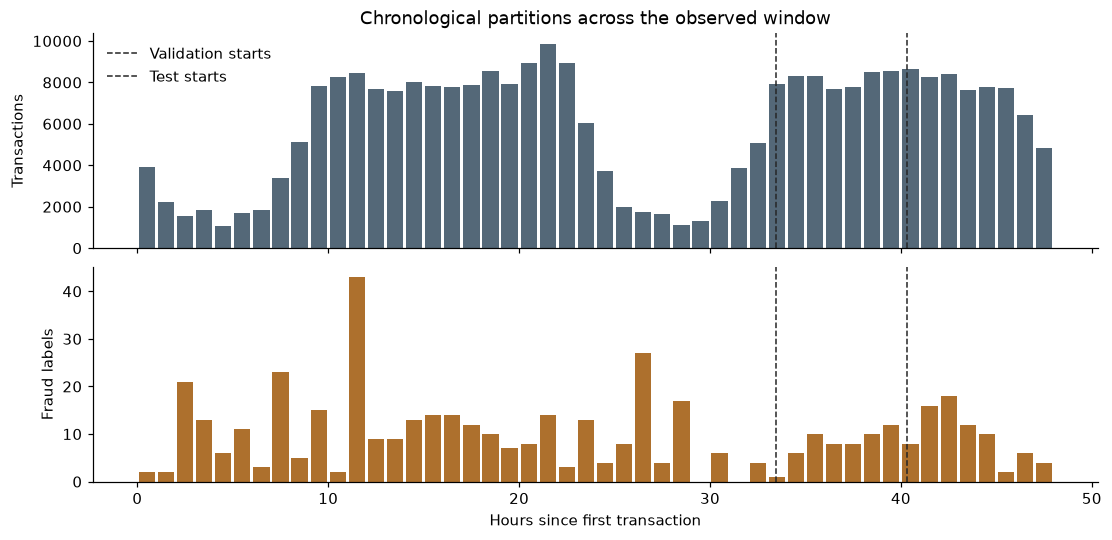

In [4]:
hourly = clean.assign(hour=(clean.Time // 3600).astype(int)).groupby("hour")[TARGET].agg(["size", "sum"])
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 4.8), layout="constrained")
ax1.bar(hourly.index + .5, hourly["size"], width=.85, color="#546878")
ax2.bar(hourly.index + .5, hourly["sum"], width=.85, color="#ad702d")
for index, frame in enumerate([validation, test]):
    for ax in (ax1, ax2):
        ax.axvline(frame.Time.min() / 3600, color="#262626", ls="--", lw=1,
                   label=["Validation starts", "Test starts"][index])
ax1.set(ylabel="Transactions", title="Chronological partitions across the observed window")
ax2.set(xlabel="Hours since first transaction", ylabel="Fraud labels")
ax1.legend(frameon=False)
plt.show()

## 3. Explore an interpretable feature

The next histogram uses **training rows only**. Each class histogram is normalized independently, so it compares the distribution of amounts within each class. The transformed horizontal axis uses `log10(1 + Amount)` to retain zero values and make the long tail readable. Training still uses the original amount.

All three classifiers use splits on numerical features, so they do not need standard scaling. Time enters the classifiers as elapsed seconds. It can capture patterns specific to this two-day dataset, which may not transfer to another period. The label never enters the feature matrix.

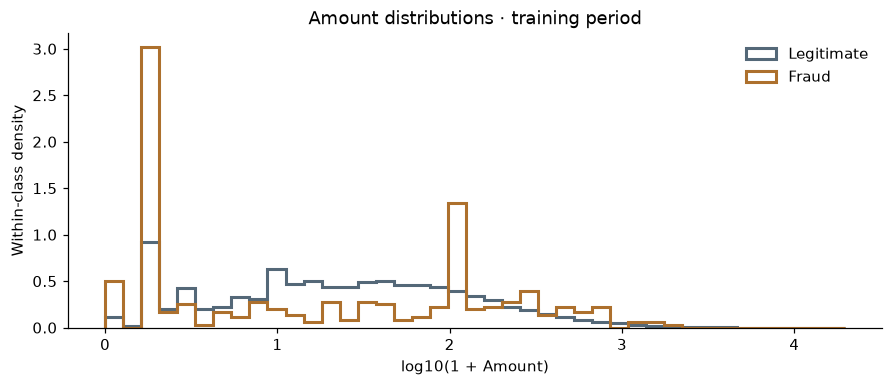

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
edges = np.linspace(0, np.log10(1 + train.Amount.max()), 42)
for label, name, color in [(0, "Legitimate", "#546878"), (1, "Fraud", "#ad702d")]:
    values = np.log10(1 + train.loc[train[TARGET] == label, "Amount"])
    ax.hist(values, bins=edges, density=True, histtype="step", lw=2, color=color, label=name)
ax.set(xlabel="log10(1 + Amount)", ylabel="Within-class density", title="Amount distributions · training period")
ax.legend(frameon=False)
plt.show()

## 4. Fit CART, Random Forest, and XGBoost

| Classifier | Where the algorithm is used | How training handles rare fraud |
|---|---|---|
| CART | One binary tree learns feature thresholds. A shallow depth and minimum leaf size limit fragmentation. | `class_weight="balanced"` gives fraud greater weight in split selection. |
| Random Forest | 64 independently fit trees learn from bootstrap samples and random feature subsets. Their output scores are averaged. | `balanced_subsample` computes class weights within each bootstrap sample. |
| XGBoost | 200 shallow trees are added sequentially. Each new tree uses gradients of the loss to improve the ensemble. | `scale_pos_weight` is the ratio of legitimate to fraud rows in training. |

The model settings are fixed for this practical. With `RETRAIN` enabled, `train.py` calls `model.fit(train[FEATURES], train[Class])` for each model. Class weights modify learning, so the resulting numbers are **uncalibrated fraud scores** even though the library exposes them through `predict_proba`. The observed class balance still governs validation and test.

In [6]:
ratio = (train[TARGET] == 0).sum() / (train[TARGET] == 1).sum()
print(f"XGBoost positive-class weight: {ratio:.2f}")
configured = build_models(train[TARGET])
for model_id, model in configured.items():
    params = model.get_params()
    shown = ["max_depth", "n_estimators", "min_samples_leaf", "class_weight", "scale_pos_weight"]
    print(NAMES[model_id], {key: params[key] for key in shown if key in params})

XGBoost positive-class weight: 496.76
CART {'max_depth': 5, 'min_samples_leaf': 20, 'class_weight': 'balanced'}
Random Forest {'max_depth': 15, 'n_estimators': 64, 'min_samples_leaf': 2, 'class_weight': 'balanced_subsample'}
XGBoost {'max_depth': 4, 'n_estimators': 200, 'scale_pos_weight': 496.7631578947368}


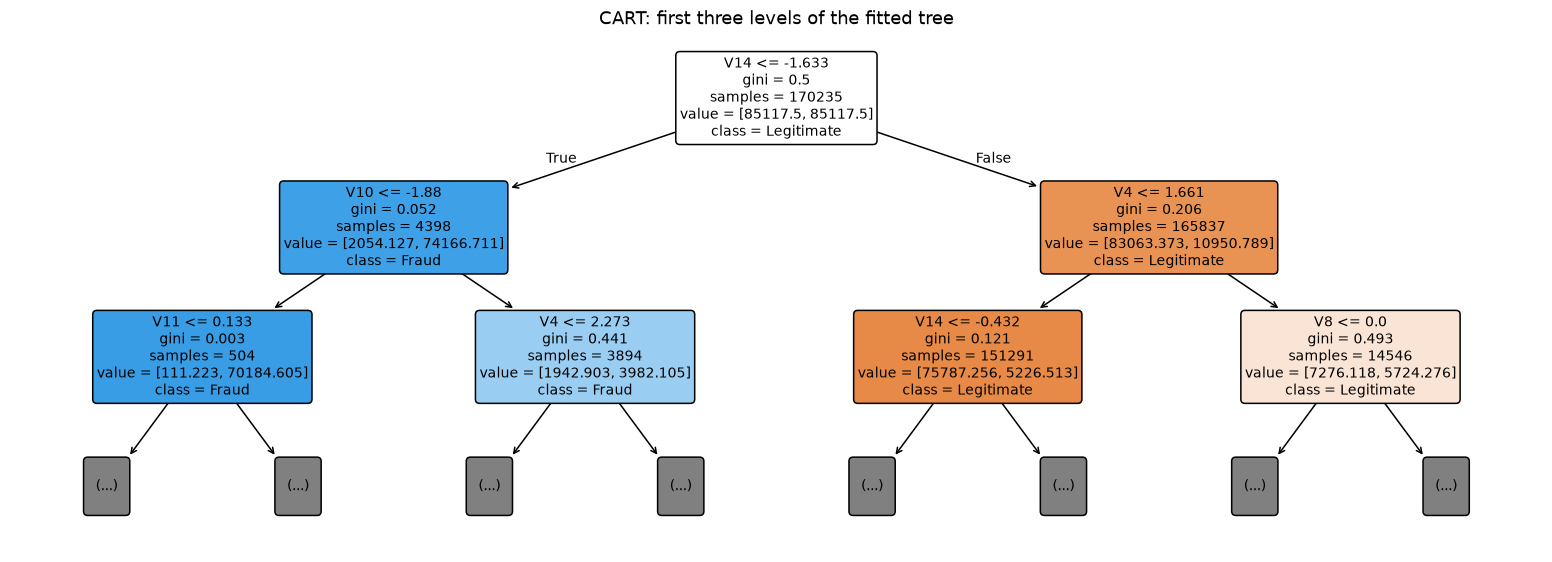

In [7]:
fig, ax = plt.subplots(figsize=(14, 5), layout="constrained")
plot_tree(models["cart"], feature_names=FEATURES, class_names=["Legitimate", "Fraud"],
          max_depth=2, filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("CART: first three levels of the fitted tree")
plt.show()

For an internal CART node, values at or below the displayed threshold follow the left branch. Larger values follow the right branch. A leaf's score is its weighted fraction of fraud. The plot truncates deeper branches to keep the rules readable. For the forest, the same kind of routing happens across all 64 trees.

## 5. Select the model and decision cutoffs using validation

**Average precision (AP)** summarizes the ranking by weighing each precision by the increase in recall. A score without ranking skill is represented by a horizontal line at the fraud prevalence. **F1** is the harmonic mean of precision and recall. We choose each model's cutoff at maximum validation F1 and choose the dashboard's default classifier by validation AP. The rule is **flag when score ≥ cutoff**. Both choices are fixed before reading the test metrics.

This cutoff treats precision and recall symmetrically. A deployment would need an explicit cost or review-capacity target.

,validation AP,alert cutoff
model,,
CART,0.6815,0.9996
Random Forest,0.7718,0.2653
XGBoost,0.7804,0.9173


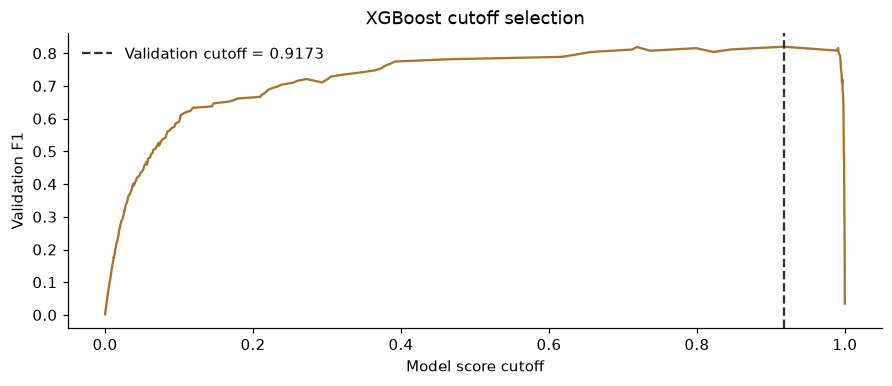

In [8]:
default_id = report["recommended"]
display(pd.DataFrame([
    {"model": m["name"], "validation AP": m["validation_ap"], "alert cutoff": m["threshold"]}
    for m in report["models"].values()
]).round(4).set_index("model"))

val_scores = scores(models[default_id], validation)
cutoff = validation_threshold(validation[TARGET], val_scores)
assert np.isclose(cutoff, report["models"][default_id]["threshold"])
p, r, cuts = precision_recall_curve(validation[TARGET], val_scores)
f = np.divide(2 * p[:-1] * r[:-1], p[:-1] + r[:-1],
              out=np.zeros_like(cuts), where=(p[:-1] + r[:-1]) > 0)
fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
ax.plot(cuts, f, color=colors[default_id])
ax.axvline(cutoff, color="#303030", ls="--", label=f"Validation cutoff = {cutoff:.4f}")
ax.set(xlabel="Model score cutoff", ylabel="Validation F1", title=f"{NAMES[default_id]} cutoff selection")
ax.legend(frameon=False)
plt.show()

## 6. Evaluate on the later holdout

- **Precision** = TP / (TP + FP). Of the alerts, how many were fraud?
- **Recall** = TP / (TP + FN). Of the frauds, how many were caught?
- **F1** combines precision and recall at the chosen threshold.
- **AP** summarizes precision across the recall curve. It depends on ranking across the entire set of thresholds.
- **Accuracy** counts all correct decisions, including the much larger legitimate class.

The full test-score file contains one row per held-out transaction after cleaning, aligned with the test split. AP in the report comes from all test scores. The dashboard uses a compact display curve, while the notebook below plots the full curve.

,ap,accuracy,precision,recall,f1,threshold
name,,,,,,
CART,0.6489,0.9995,0.8947,0.6892,0.7786,0.9996
Random Forest,0.8078,0.9995,0.8750,0.7568,0.8116,0.2653
XGBoost,0.7984,0.9996,0.9167,0.7432,0.8209,0.9173


Always-legitimate accuracy: 99.8696%; recall: 0%
Default from validation: XGBoost
Highest test AP: Random Forest


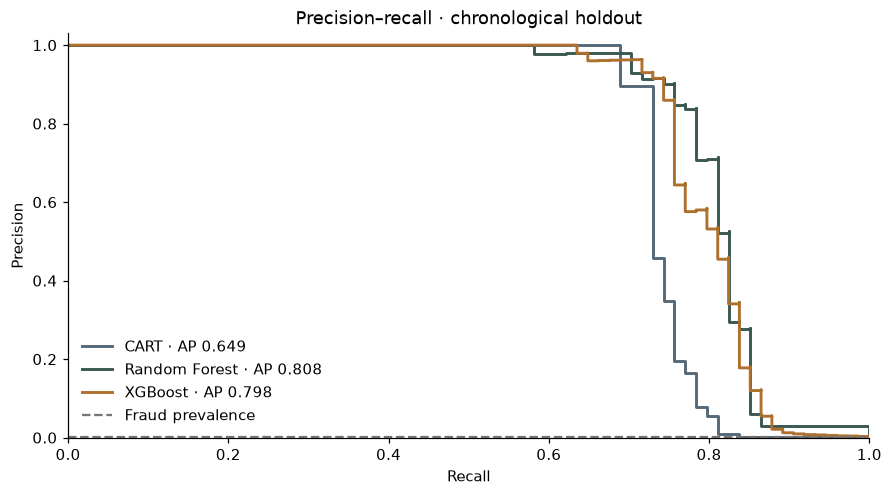

In [9]:
saved = pd.read_csv(ARTIFACTS / "test_scores.csv.gz")
assert np.array_equal(saved[TARGET].to_numpy(), test[TARGET].to_numpy())
benchmark = pd.DataFrame(report["models"]).T[["name", "ap", "accuracy", "precision", "recall", "f1", "threshold"]]
display(benchmark.set_index("name").astype(float).round(4))
print(f"Always-legitimate accuracy: {(1 - test[TARGET].mean()):.4%}; recall: 0%")
print("Default from validation:", NAMES[default_id])
print("Highest test AP:", benchmark.sort_values("ap", ascending=False).iloc[0]["name"])

fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
for mid, name in NAMES.items():
    p, r, _ = precision_recall_curve(saved[TARGET], saved[mid])
    ax.step(r[::-1], p[::-1], where="post", lw=1.9, color=colors[mid],
            label=f'{name} · AP {report["models"][mid]["ap"]:.3f}')
ax.axhline(saved[TARGET].mean(), color="#777", ls="--", label="Fraud prevalence")
ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.03), title="Precision–recall · chronological holdout")
ax.legend(frameon=False)
plt.show()

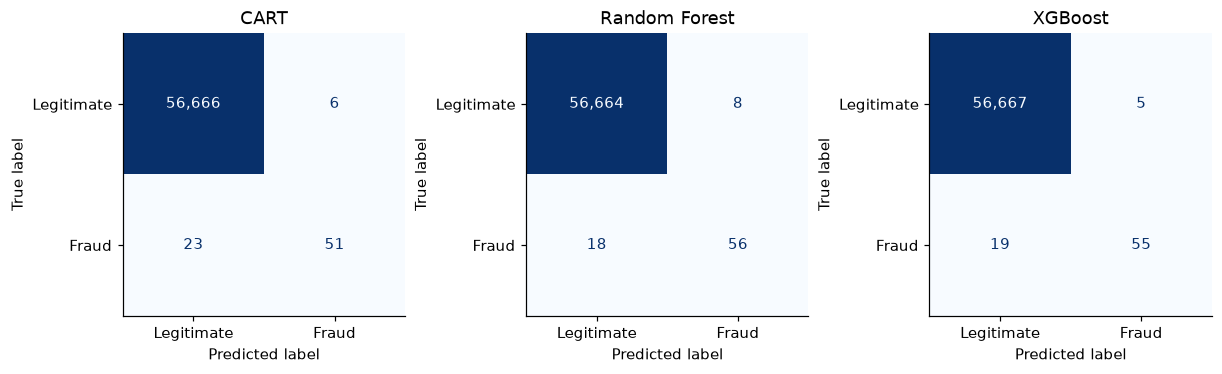

CART: caught 51 frauds, missed 23, generated 6 false alerts.
Random Forest: caught 56 frauds, missed 18, generated 8 false alerts.
XGBoost: caught 55 frauds, missed 19, generated 5 false alerts.


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), layout="constrained")
for (mid, name), ax in zip(NAMES.items(), axes):
    matrix = np.array(report["models"][mid]["matrix"])
    ConfusionMatrixDisplay(matrix, display_labels=["Legitimate", "Fraud"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format=",d")
    ax.set_title(name)
plt.show()

for model in report["models"].values():
    (tn, fp), (fn, tp) = model["matrix"]
    print(f'{model["name"]}: caught {tp} frauds, missed {fn}, generated {fp} false alerts.')

In each confusion matrix the **rows are actual labels** and the **columns are predicted labels**. The top-right cell is the false-alert count, and the bottom-left cell is the missed-fraud count. The false-alert count is easy to overlook in a matrix dominated by true negatives, so the counts are also printed explicitly. A higher AP on test does not change the default model because the test set did not select it. Differences measured on only 74 frauds should be interpreted as measurements for this particular period.

## 7. Explain model behavior

### Global feature importance

For CART and Random Forest, `feature_importances_` measures normalized impurity reduction from splits. For XGBoost's tree model, it measures normalized average split gain. Compare ranks within each model. Importance does not explain the direction of an individual alert. A PCA component's high rank does not disclose the original data behind it.

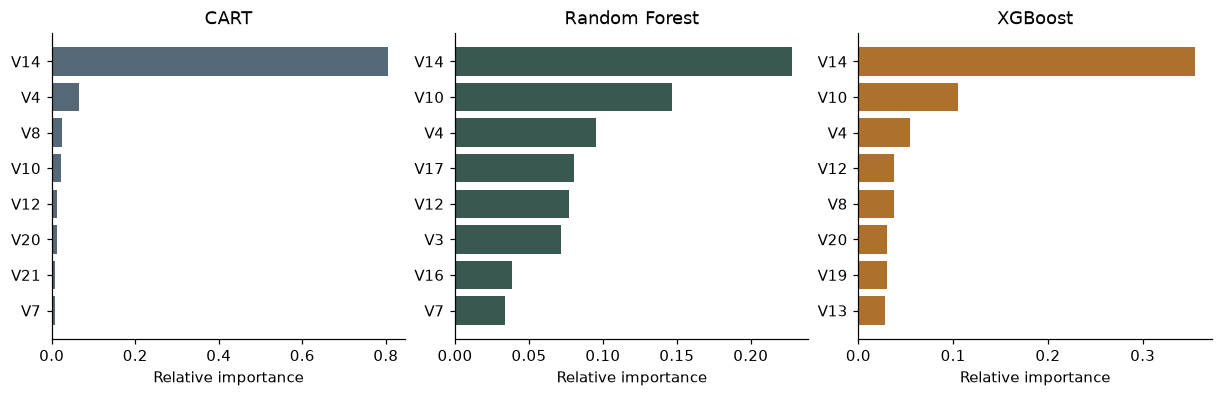

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), layout="constrained")
for (mid, name), ax in zip(NAMES.items(), axes):
    items = list(reversed(report["models"][mid]["importance"]))
    ax.barh([item["name"] for item in items], [item["value"] for item in items], color=colors[mid])
    ax.set(title=name, xlabel="Relative importance")
plt.show()

### Local explanation for a flagged transaction

The selected held-out example was flagged by the validation-selected model and has a recorded fraud label. Two explanation methods back the same dashboard view:

- **CART and Random Forest.** Each split contributes the change in weighted fraud score from parent to child to the feature used by that split. The sum from root to leaf reconstructs the CART score. Averaging roots and paths across the trees reconstructs the Random Forest score.
- **XGBoost.** Native TreeSHAP returns a baseline and signed feature contributions in raw **log-odds**. The sigmoid of their sum reconstructs the XGBoost score.

Positive contributions push the model's score upward. Negative contributions push it downward. This is attribution to the fitted classifier, not proof that a feature causes fraud.

CART score = 0.999599 | reconstructed = 0.999599 | Tree path contributions
Random Forest score = 0.780835 | reconstructed = 0.780835 | Tree path contributions
XGBoost score = 0.999862 | reconstructed = 0.999862 | TreeSHAP


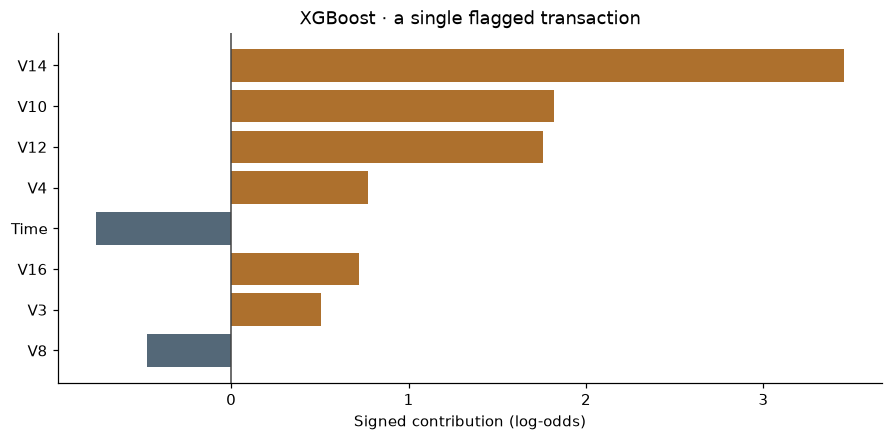

Baseline in log-odds: 1.2161


In [12]:
case = next(case for case in report["examples"] if case["label"] == "Flagged fraud")
row = pd.DataFrame([case["values"]], columns=FEATURES)
for mid, model in models.items():
    value = scores(model, row)[0]
    ex = explain(mid, model, row)
    reconstructed = 1 / (1 + math.exp(-ex["total"])) if mid == "xgb" else ex["total"]
    assert np.isclose(value, reconstructed, atol=1e-6)
    print(f'{NAMES[mid]} score = {value:.6f} | reconstructed = {reconstructed:.6f} | {ex["method"]}')

ex = explain(default_id, models[default_id], row)
factors = pd.DataFrame(ex["features"][:8]).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.9), layout="constrained")
ax.barh(factors.name, factors.value, color=np.where(factors.value > 0, "#ad702d", "#546878"))
ax.axvline(0, color="#444", lw=1)
ax.set(xlabel=f"Signed contribution ({ex['unit']})", title=f"{NAMES[default_id]} · a single flagged transaction")
plt.show()
print(f'Baseline in {ex["unit"]}: {ex["base"]:.4f}')

## 8. Demonstrate ScamShield

1. Run `python app.py` and open the local dashboard. Start with **Models** to explain why precision and recall matter for an imbalanced dataset.
2. In **Assess a transaction**, use **Flagged fraud** and run each classifier on the same fields. Compare the outputs and the different explanation units.
3. Load **False alert** or **Missed fraud** if available and discuss how the cutoff changes which transactions a reviewer sees. The example's name reflects the default model.
4. Edit **Amount** or a PCA feature and re-run the assessment. The edited input is an experiment and has no recorded fraud label.

The benchmark covers a short historical slice and relies on principal components whose mappings are unavailable. Raw merchant or cardholder fields cannot be converted to these anonymized features with this dataset. Production use would require current representative data, obtainable inputs, probability calibration if probabilities are needed, and validation against actual review constraints.